# One-sample correlations: which gene pairs are co-expressed?

This tutorial estimates gene-gene correlations within a single population of cells and tests each one against zero. A typical use is finding the genes whose expression tracks a transcription factor in one cell type.

**What the one-sample test does**

- It runs when `ht_2d_moments` is called without a treatment (`treatment=None`).
- The estimate is the average of the per-group correlations, weighted by each group's cell count. Here every donor is a group.
- The null hypothesis is that the correlation is zero.
- It takes no covariates. A one-sample average has nothing to adjust: to describe a particular population (one condition, one cell type, healthy donors only), subset the data to that population first.

**Two things to keep in mind when reading the results**

- Because groups are weighted by cell count, a donor with many cells has more influence on the estimate.
- By default, the p-value reflects only the uncertainty from sampling cells within each donor. That supports a statement about *these* donors. It does not reflect variation between donors, so a pair can be significant because of one or two of them.

To make a statement about the population the donors were drawn from, resample donors as well (`resample_rep=True`). The later sections show this, together with a per-donor check.

To compare correlations between conditions instead, pass a treatment; see the differential correlation guide in the documentation.

Data: https://memento-examples.s3.us-west-2.amazonaws.com/pbmc-ifnb/interferon_filtered.h5ad (PBMCs from 8 donors, with and without interferon-β).

In [1]:
import itertools

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc

import memento

In [2]:
data_path = './'  # folder containing interferon_filtered.h5ad

### Read the data and select the population

`adata.X` must hold raw integer counts in a sparse matrix, ideally with all detected genes.

The one-sample test describes whatever cells you give it, so select the population here: unstimulated CD14+ monocytes.

In [3]:
adata = sc.read(data_path + 'interferon_filtered.h5ad')
adata = adata[(adata.obs['cell'] == 'CD14+ Monocytes') & (adata.obs['stim'] == 'ctrl')].copy()
adata.obs['ind'] = adata.obs['ind'].astype(str)
print(adata.shape)
adata.obs['ind'].value_counts()

/home/ubuntu/my_python/lib/python3.10/site-packages/anndata/__init__.py:51: FutureWarning: `anndata.read` is deprecated, use `anndata.read_h5ad` instead. `ad.read` will be removed in mid 2024.
  warnings.warn(


(2763, 35635)


ind
1015    778
1244    415
1256    389
1016    368
1488    292
107     207
101     202
1039    112
Name: count, dtype: int64

### Set up memento and group cells by donor

`capture_rate` is the overall UMI capture efficiency (0.07 for this 10x v1 dataset). Each donor (`ind`) becomes one group.

`min_perc_group=.9` keeps genes that pass the expression filter in at least 90% of donors.

In [4]:
adata.obs['capture_rate'] = 0.07
memento.setup_memento(adata, q_column='capture_rate')
memento.create_groups(adata, label_columns=['ind'])
memento.compute_1d_moments(adata, min_perc_group=.9)
print(adata.shape[1], 'genes retained')

1221 genes retained


### Choose the gene pairs

Pair each transcription factor with every other retained gene. Only genes that survived filtering can be tested, so check that the factors you ask for are in the list. Here STAT1, for example, does not pass the filter in unstimulated monocytes.

Each pair is bootstrapped separately, so runtime grows with the number of pairs. For long lists of transcription factors, run them in batches.

In [5]:
tfs = [tf for tf in ['IRF7', 'CEBPB'] if tf in adata.var_names]
gene_pairs = [(tf, gene) for tf, gene in itertools.product(tfs, adata.var_names) if tf != gene]
print(tfs, len(gene_pairs), 'pairs')

['IRF7', 'CEBPB'] 2440 pairs


### Run the one-sample test

Leaving out `treatment` requests the one-sample test. Increase `num_cpus` to match your machine.

With a CUDA GPU and the GPU extra installed (`pip install 'memento-de[gpu]'`), set `backend = 'gpu'`. The estimates are the same and the p-values agree up to bootstrap noise, and the run takes seconds instead of minutes. `num_cpus` is ignored on the GPU.

In [6]:
backend = 'cpu'  # or 'gpu'

memento.compute_2d_moments(adata, gene_pairs)
memento.ht_2d_moments(
    adata,
    treatment=None,
    num_boot=5000,
    num_cpus=4,
    backend=backend,
    random_state=0,
    verbose=1)
result = memento.get_2d_ht_result(adata)
result.head()

[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.


[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:   10.0s


[Parallel(n_jobs=4)]: Done 192 tasks      | elapsed:   28.9s


[Parallel(n_jobs=4)]: Done 442 tasks      | elapsed:  1.0min


[Parallel(n_jobs=4)]: Done 792 tasks      | elapsed:  1.8min


[Parallel(n_jobs=4)]: Done 1242 tasks      | elapsed:  3.1min


[Parallel(n_jobs=4)]: Done 1792 tasks      | elapsed:  5.4min


[Parallel(n_jobs=4)]: Done 2440 out of 2440 | elapsed:  8.0min finished


,gene_1,gene_2,tx,corr_coef,corr_se,corr_pval
0,IRF7,ISG15,intercept,0.424295,0.060036,2.555165e-12
1,IRF7,AURKAIP1,intercept,0.014017,0.113452,9.024787e-01
2,IRF7,MRPL20,intercept,0.084236,0.113881,4.907348e-01
3,IRF7,SSU72,intercept,-0.069938,0.092810,4.546639e-01
4,IRF7,RER1,intercept,0.010683,0.100588,9.154197e-01


`corr_coef` is the cell-count-weighted mean correlation across donors, `corr_se` its bootstrap standard error, and `corr_pval` the unadjusted p-value against zero. The `tx` column reads `intercept` for one-sample tests.

P-values are not corrected for multiple testing. Apply a correction within each transcription factor:

In [7]:
result['corr_fdr'] = result.groupby('gene_1')['corr_pval'].transform(memento.util._fdrcorrect)
(result['corr_fdr'] < 0.1).groupby(result['gene_1']).sum()

gene_1
CEBPB    478
IRF7      32
Name: corr_fdr, dtype: int64

### Check that donors agree

`get_2d_moments` returns the correlation estimated within each donor. Use it to see whether a significant pair is supported across donors or carried by a few of them.

Below, `donor_agreement` is the fraction of donors whose correlation has the same sign as the overall estimate. Donors where the correlation could not be estimated are left out of the fraction. So are values of exactly 1 or -1: those are estimates that fell outside [-1, 1] and were clipped, which happens mostly in donors with few cells. The test excludes them for the same reason.

In [8]:
per_donor = memento.get_2d_moments(adata, groupby='ind').set_index(['gene_1', 'gene_2'])
per_donor = per_donor.where(per_donor.abs() < 1)  # drop clipped estimates
per_donor.head()

ind_1016  ind_1256  ind_1015   ind_101  ind_1244  ind_1488  \
gene_1 gene_2                                                                 
IRF7   ISG15     0.608254  0.545386  0.481540  0.431315  0.057959  0.877065   
       AURKAIP1 -0.164313  0.226665 -0.037579  0.015527 -0.084026       NaN   
       MRPL20    0.133721  0.164325 -0.125096  0.085751 -0.175412  0.295116   
       SSU72    -0.182893 -0.058881 -0.086262 -0.064915  0.112507 -0.424727   
       RER1      0.199787 -0.133626 -0.020311 -0.038087  0.231782       NaN   

                 ind_1039   ind_107  
gene_1 gene_2                        
IRF7   ISG15     0.757361  0.066560  
       AURKAIP1       NaN -0.198869  
       MRPL20    0.083613  0.147281  
       SSU72    -0.368843  0.173003  
       RER1     -0.268467  0.307240

In [9]:
result = result.set_index(['gene_1', 'gene_2'])
same_sign = np.sign(per_donor).eq(np.sign(result['corr_coef']), axis=0)
result['n_donors'] = per_donor.notna().sum(axis=1)
result['donor_agreement'] = same_sign.sum(axis=1) / result['n_donors']
result = result.reset_index()

supported = result.query('corr_fdr < 0.1 & donor_agreement >= 0.75')
print(len(result.query('corr_fdr < 0.1')), 'pairs at FDR < 0.1;', len(supported), 'of them agree in sign in at least 75% of donors')
supported.sort_values('corr_pval').head(20)

510 pairs at FDR < 0.1; 481 of them agree in sign in at least 75% of donors


,gene_1,gene_2,tx,corr_coef,corr_se,corr_pval,corr_fdr,n_donors,donor_agreement
1995,CEBPB,CD63,intercept,0.412601,0.033236,3.031353e-34,1.926443e-31,8,1.000
1923,CEBPB,FTH1,intercept,0.308057,0.024954,3.158104e-34,1.926443e-31,8,1.000
1719,CEBPB,ATP6V1F,intercept,0.402358,0.034349,6.685262e-31,2.718673e-28,8,1.000
2369,CEBPB,FTL,intercept,0.299510,0.026877,3.465949e-28,1.057114e-25,8,1.000
1531,CEBPB,ANXA5,intercept,0.348724,0.032081,6.866037e-27,1.675313e-24,8,1.000
1776,CEBPB,CTSB,intercept,0.334012,0.030745,1.448956e-26,2.946211e-24,8,0.875
2116,CEBPB,B2M,intercept,0.272952,0.025960,2.704261e-25,4.713141e-23,8,1.000
2197,CEBPB,EIF4A1,intercept,0.363950,0.037335,5.801618e-22,8.056154e-20,8,1.000
1831,CEBPB,CTSL,intercept,0.325806,0.033296,5.943064e-22,8.056154e-20,8,0.875
2082,CEBPB,LGALS3,intercept,0.291953,0.030634,2.351421e-21,2.642967e-19,8,1.000


### From these donors to the population: resample donors

The test above treats the 8 donors as fixed. Its p-value asks: given the cells we happened to sample, is the weighted mean correlation in *these* donors different from zero? Most questions are about the population the donors came from, such as CD14+ monocytes in healthy people. Answering that requires the standard error to include how much the correlation varies from donor to donor.

`resample_rep=True` adds this second level. Each bootstrap draw samples donors with replacement, then takes a cell-bootstrap replicate within each sampled donor. The estimate itself is unchanged; only the standard error and p-value change.

In [10]:
memento.ht_2d_moments(
    adata,
    treatment=None,
    resample_rep=True,
    num_boot=5000,
    num_cpus=4,
    backend=backend,
    random_state=0,
    verbose=1)
donor_level = memento.get_2d_ht_result(adata)
donor_level['corr_fdr'] = donor_level.groupby('gene_1')['corr_pval'].transform(memento.util._fdrcorrect)

compare = result.merge(
    donor_level[['gene_1', 'gene_2', 'corr_coef', 'corr_se', 'corr_pval', 'corr_fdr']],
    on=['gene_1', 'gene_2'], suffixes=('_cells', '_donors'))
print('same estimate:', np.allclose(compare['corr_coef_cells'], compare['corr_coef_donors'], equal_nan=True))
print('median SE ratio (donors / cells): %.2f' % (compare['corr_se_donors'] / compare['corr_se_cells']).median())
pd.DataFrame({
    'FDR < 0.1, cells only': (compare['corr_fdr_cells'] < 0.1).groupby(compare['gene_1']).sum(),
    'FDR < 0.1, donors resampled': (compare['corr_fdr_donors'] < 0.1).groupby(compare['gene_1']).sum(),
})

[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.


[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:    6.0s


[Parallel(n_jobs=4)]: Done 192 tasks      | elapsed:   28.9s


[Parallel(n_jobs=4)]: Done 442 tasks      | elapsed:  1.2min


[Parallel(n_jobs=4)]: Done 792 tasks      | elapsed:  2.1min


[Parallel(n_jobs=4)]: Done 1242 tasks      | elapsed:  3.4min


[Parallel(n_jobs=4)]: Done 1792 tasks      | elapsed:  5.4min


same estimate: True
median SE ratio (donors / cells): 1.30


[Parallel(n_jobs=4)]: Done 2440 out of 2440 | elapsed:  7.2min finished


,"FDR < 0.1, cells only","FDR < 0.1, donors resampled"
gene_1,,
CEBPB,478,255
IRF7,32,7


The pairs that remain significant with donors resampled are the ones that support a population-level statement. Pairs that are significant only at the cell level may still be real in these donors, but the 8 donors do not show that they generalize.

In [11]:
compare.query('corr_fdr_donors < 0.1').sort_values('corr_pval_donors')[
    ['gene_1', 'gene_2', 'corr_coef_cells', 'corr_se_cells', 'corr_se_donors', 'corr_fdr_donors', 'donor_agreement']].head(20)

,gene_1,gene_2,corr_coef_cells,corr_se_cells,corr_se_donors,corr_fdr_donors,donor_agreement
2369,CEBPB,FTL,0.299510,0.026877,0.036355,2.967742e-13,1.000
1923,CEBPB,FTH1,0.308057,0.024954,0.038729,1.273163e-12,1.000
1719,CEBPB,ATP6V1F,0.402358,0.034349,0.054639,8.497336e-11,1.000
2197,CEBPB,EIF4A1,0.363950,0.037335,0.050183,1.952530e-10,1.000
1531,CEBPB,ANXA5,0.348724,0.032081,0.048672,3.538583e-10,1.000
2082,CEBPB,LGALS3,0.291953,0.030634,0.042559,1.659343e-09,1.000
1969,CEBPB,GAPDH,0.260972,0.031783,0.037829,1.659343e-09,1.000
2126,CEBPB,ANXA2,0.293069,0.035078,0.043230,2.422796e-09,1.000
1831,CEBPB,CTSL,0.325806,0.033296,0.048025,2.422796e-09,0.875
1995,CEBPB,CD63,0.412601,0.033236,0.061971,4.620915e-09,1.000


**Donor-level covariates.** If donors differ in something that affects the correlation, such as age, sex or processing batch, pass it as `covariate` (one row per donor, in the order of `memento.get_groups(adata)`) together with `resample_rep=True`. Variation between donors that the covariates explain is then removed before donors are resampled. Covariates do not change the estimate, and without `resample_rep` they have no effect. This dataset has no donor metadata, so none are used here.

**Few donors.** With 8 donors, the donor bootstrap is coarse. Its standard errors are themselves noisy and tend to be somewhat too small, so treat borderline pairs with care. More donors help more than more cells per donor.

### Plot

Grey points are all tested pairs, plotted with the donor-resampled p-value. Coloured points pass FDR < 0.1 with donors resampled.

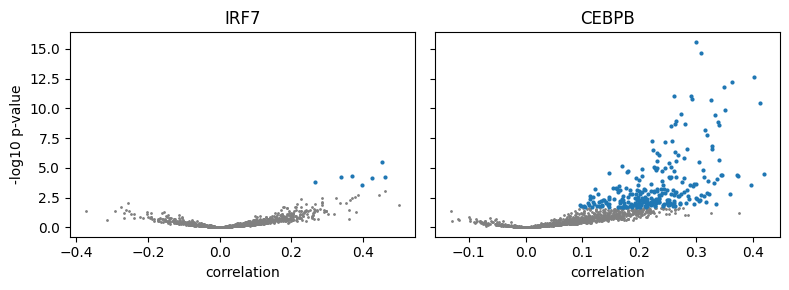

In [12]:
fig, axes = plt.subplots(1, len(tfs), figsize=(4 * len(tfs), 3), sharey=True, squeeze=False)
for ax, tf in zip(axes[0], tfs):
    df = compare[compare['gene_1'] == tf]
    hits = df[df['corr_fdr_donors'] < 0.1]
    ax.scatter(df['corr_coef_cells'], -np.log10(df['corr_pval_donors']), s=1, color='grey')
    ax.scatter(hits['corr_coef_cells'], -np.log10(hits['corr_pval_donors']), s=4)
    ax.set_title(tf)
    ax.set_xlabel('correlation')
axes[0][0].set_ylabel('-log10 p-value')
plt.tight_layout()

### Notes

- **Choosing the population.** Covariates such as disease status or condition are handled by subsetting before `create_groups`, as done here for unstimulated cells. Repeat the analysis on another subset to describe another population.
- **Comparing populations.** To test whether a correlation differs between two conditions, keep both in the data and pass the condition as `treatment` to `ht_2d_moments`. Covariates are used in that test.
- **Which p-value to report.** Use the donor-resampled test for claims about the population; the cell-level test describes only the donors in hand.